# Chronos-2 zero-shot forecasts: 30-year mortgage rate and commercial bank deposits

This notebook produces the Chronos side of the project: forecasts from a pretrained AI model that is never fitted to our data. The ARIMA side follows the same evaluation design, so the two sets of forecasts line up row for row.

**Evaluation design shared by both models**

| Item | Setting |
|---|---|
| Series | `MORTGAGE30US` and `DPSACBW027SBOG` (both weekly, from FRED) |
| History each model may use | From `HISTORY_START` up to the forecast origin, and nothing after it |
| Test period | The last `N_WINDOWS x HORIZON` = 104 weeks of each series |
| Forecast horizon | `HORIZON` = 13 weeks (one quarter) |
| Forecast origins | 8 origins, 13 weeks apart, so the test windows do not overlap |
| Scale | Forecasts are scored in the original units (percent, $ billions) |
| Point forecast | Median for Chronos, the usual mean forecast for ARIMA |
| Interval | 80% prediction interval (10th to 90th percentile) |
| Metrics | MAE, RMSE, MAE relative to a naive forecast, 80% interval coverage |
| Baseline | Naive forecast: the last observed value carried forward |

## 1. Settings

Everything that defines the evaluation is set here. If you and your partner change one of these values, change it on both sides.

In [11]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from chronos import Chronos2Pipeline

DATA_DIR = Path("data")
OUT_DIR = Path("output")
OUT_DIR.mkdir(exist_ok=True)

SERIES = {
    "mortgage30": {
        "file": "MORTGAGE30US.csv",
        "column": "MORTGAGE30US",
        "label": "30-year mortgage rate (%)",
    },
    "deposits": {
        "file": "Deposits.csv",
        "column": "DPSACBW027SBOG",
        "label": "Deposits, all commercial banks ($ billions)",
    },
}

HISTORY_START = "2000-01-01"  # earliest data either model may use
CHRONOS_COLUMNS = ["item_id", "timestamp", "target"]  # the only columns passed to Chronos
HORIZON = 13                  # weeks ahead in each forecast
N_WINDOWS = 8                 # number of forecast origins
MODEL_ID = "amazon/chronos-2"

## 2. Load the data

Chronos expects a "long" table with three columns: an id for the series, a timestamp, and the value. It also requires evenly spaced timestamps. The mortgage survey is weekly, but its release day moves around holidays (and moved from Friday to Thursday years ago), so `load_series` places each series on an exact 7-day grid in the `timestamp` column. The values are not changed, and the original FRED date is kept in `fred_date` so the saved results can be matched to the raw files by date.

In [12]:
def load_series(name):
    info = SERIES[name]
    raw = pd.read_csv(DATA_DIR / info["file"], parse_dates=["observation_date"])
    raw = raw.sort_values("observation_date").reset_index(drop=True)

    # One observation per week, so an exact weekly grid ending on the last date fits every row.
    grid = pd.date_range(end=raw["observation_date"].iloc[-1], periods=len(raw), freq="7D")
    shift_days = (raw["observation_date"] - grid).abs().dt.days.max()
    assert shift_days <= 3, f"{name}: dates are not one-per-week (largest shift {shift_days} days)"

    df = pd.DataFrame({
        "item_id": name,
        "timestamp": grid,                     # evenly spaced dates, used by Chronos
        "target": raw[info["column"]].astype(float),
        "fred_date": raw["observation_date"],  # original FRED dates, used in the saved results
    })
    assert df["target"].notna().all(), f"{name}: missing values"
    return df[df["timestamp"] >= HISTORY_START].reset_index(drop=True)


data = {name: load_series(name) for name in SERIES}

for name, df in data.items():
    print(f"{name}: {len(df)} weeks, {df['timestamp'].iloc[0].date()} to {df['timestamp'].iloc[-1].date()}")

mortgage30: 1402 weeks, 2000-01-06 to 2026-11-12
deposits: 1401 weeks, 2000-01-05 to 2026-11-04


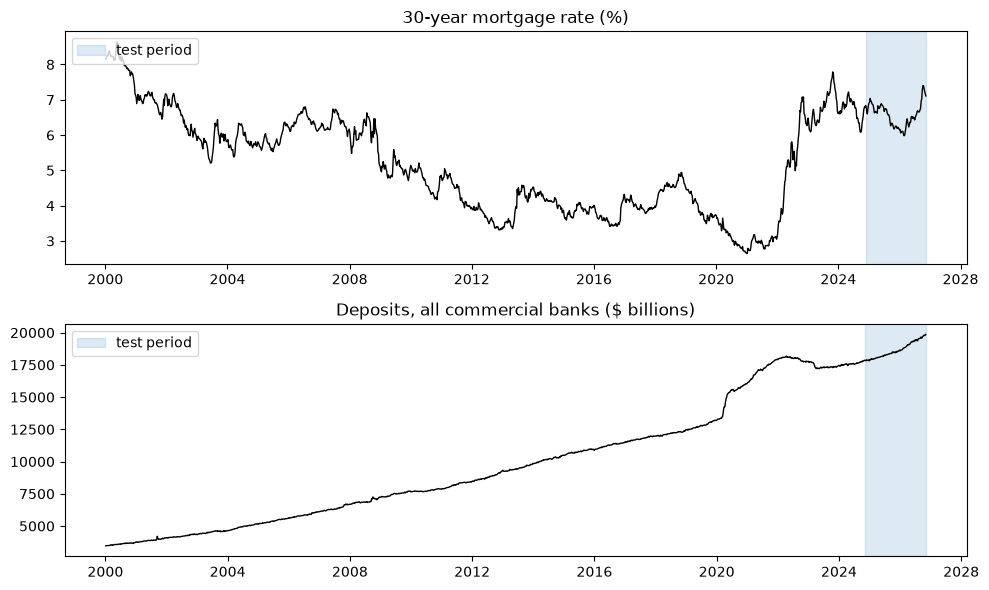

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
for ax, (name, df) in zip(axes, data.items()):
    test_start = df["timestamp"].iloc[-N_WINDOWS * HORIZON]
    ax.plot(df["timestamp"], df["target"], color="black", linewidth=1)
    ax.axvspan(test_start, df["timestamp"].iloc[-1], color="tab:blue", alpha=0.15, label="test period")
    ax.set_title(SERIES[name]["label"])
    ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(OUT_DIR / "series_overview.svg")
plt.show()

## 3. How Chronos produces a forecast

**The short version.** ARIMA learns from one series: you choose the orders $(p, d, q)$, estimate the coefficients from that series, and forecast from the fitted equation. Chronos-2 learned its parameters once, in advance, from a very large collection of other time series (real and synthetic). At forecast time it reads our series as input and outputs a forecast. No parameter is estimated from our data. That is what **zero-shot** means.

**What happens to the series inside the model**

1. **Scaling.** The history is standardized: subtract its mean and divide by its standard deviation, $\tilde{x}_t = (x_t - \mu)/\sigma$, followed by an $\operatorname{arcsinh}$ transform that damps extreme values. This is why one model can handle a rate near 7 and a dollar series near 20,000. The forecast is converted back to the original units at the end.
2. **Patching.** The scaled history is cut into consecutive blocks of observations called patches. Each patch is turned into a vector (an embedding), so the model reads a sequence of patches instead of single points.
3. **Transformer encoder.** Attention layers let every patch draw on every other patch in the history. This is where the model picks up level, trend, seasonality and recent momentum. It plays the role that the autocorrelation structure plays in ARIMA, except that the patterns it can recognize were learned during pretraining.
4. **Quantile output.** For each future week the model outputs a set of quantiles directly (for example the 10th, 50th and 90th percentiles). The model was trained by minimizing the quantile (pinball) loss, the loss function whose minimizer is the quantile.

**What we take from the output**

- Point forecast: the median (the 0.5 quantile).
- 80% prediction interval: the 0.1 and 0.9 quantiles.

**Side by side**

| | ARIMA | Chronos-2 |
|---|---|---|
| Parameters come from | Our series (maximum likelihood) | Pretraining on other series, then frozen |
| Analyst choices | Differencing, orders $p, d, q$, transformations | Almost none: history length and horizon |
| Model form | Explicit linear equation in past values and past errors | Neural network with about 120 million parameters |
| Stationarity | Must difference or transform first | No differencing; the model scales the raw series itself |
| Uncertainty | Intervals from the model's error variance, assuming normal errors | Quantiles output directly, no distributional assumption |
| Interpretability | Coefficients can be read and tested | Not interpretable in the same way |

Reference: Ansari et al. (2025), *Chronos-2: From Univariate to Universal Forecasting*, arXiv:2510.15821.

## 4. Load the pretrained model

The first run downloads the weights; after that they are read from disk. The cell also prints the settings stored inside the model, so the numbers quoted in the report come from the model itself.

In [14]:
pipeline = Chronos2Pipeline.from_pretrained(MODEL_ID, device_map="cpu")

config = pipeline.model.chronos_config
n_parameters = sum(p.numel() for p in pipeline.model.parameters())

print(f"Parameters:               {n_parameters / 1e6:.0f} million")
print(f"Patch size:               {config.input_patch_size} observations")
print(f"Longest history it reads: {config.context_length} observations")
print(f"arcsinh after scaling:    {config.use_arcsinh}")
print(f"Quantiles it was trained to output: {config.quantiles}")

Loading weights: 100%|██████████| 170/170 [00:00<00:00, 3025.94it/s]

Parameters:               119 million
Patch size:               16 observations
Longest history it reads: 8192 observations
arcsinh after scaling:    True
Quantiles it was trained to output: [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]


## 5. One forecast, step by step

Before running the full evaluation, make a single forecast so the inputs and outputs are visible: hide the last 13 weeks of the mortgage series, give Chronos everything before them, and ask for 13 weeks.

In [15]:
df = data["mortgage30"]
context = df.iloc[:-HORIZON]   # what the model sees
actual = df.iloc[-HORIZON:]    # what really happened

pred = pipeline.predict_df(
    context[CHRONOS_COLUMNS],
    prediction_length=HORIZON,
    quantile_levels=[0.1, 0.5, 0.9],
    id_column="item_id",
    timestamp_column="timestamp",
    target="target",
)
pred

,item_id,timestamp,target_name,predictions,0.1,0.5,0.9
0,mortgage30,2026-08-20,target,6.714422,6.606050,6.714422,6.792483
1,mortgage30,2026-08-27,target,6.713547,6.583509,6.713547,6.824802
2,mortgage30,2026-09-03,target,6.707903,6.534867,6.707903,6.858605
3,mortgage30,2026-09-10,target,6.708708,6.517155,6.708708,6.877900
4,mortgage30,2026-09-17,target,6.708057,6.495793,6.708057,6.914128
5,mortgage30,2026-09-24,target,6.708938,6.471131,6.708938,6.937955
6,mortgage30,2026-10-01,target,6.709790,6.454043,6.709790,6.962449
7,mortgage30,2026-10-08,target,6.709228,6.435615,6.709228,6.983591
8,mortgage30,2026-10-15,target,6.708058,6.412796,6.708058,7.008955
9,mortgage30,2026-10-22,target,6.711495,6.398427,6.711495,7.020816


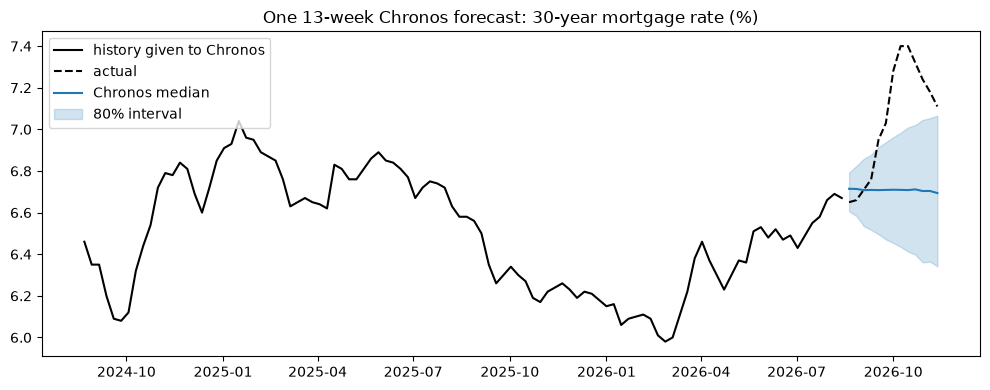

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
recent = context.tail(104)
ax.plot(recent["timestamp"], recent["target"], color="black", label="history given to Chronos")
ax.plot(actual["timestamp"], actual["target"], color="black", linestyle="--", label="actual")
ax.plot(pred["timestamp"], pred["0.5"], color="tab:blue", label="Chronos median")
ax.fill_between(pred["timestamp"], pred["0.1"], pred["0.9"], color="tab:blue", alpha=0.2, label="80% interval")
ax.set_title("One 13-week Chronos forecast: " + SERIES["mortgage30"]["label"])
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(OUT_DIR / "single_forecast_mortgage30.svg")
plt.show()

## 6. Rolling-origin evaluation

One forecast says little, so we repeat it from 8 different starting points (origins). At each origin the model sees the history up to that week only and forecasts the next 13 weeks. The 8 windows cover the last 104 weeks without overlapping.

Every forecast is stored as one row in a common format: `series, model, window, origin, timestamp, h, actual, forecast, lo80, hi80`. Here `origin` is the last date in the history, `timestamp` is the date being forecast (both are original FRED dates), and `h` is the number of weeks ahead (1 to 13). ARIMA forecasts saved in the same columns can be stacked under these rows.

In [17]:
def window_positions(n_obs):
    # Row position where each test window starts, earliest window first.
    first = n_obs - N_WINDOWS * HORIZON
    return [first + w * HORIZON for w in range(N_WINDOWS)]


def chronos_forecasts(name):
    df = data[name]
    rows = []
    for window, start in enumerate(window_positions(len(df)), start=1):
        context = df.iloc[:start]
        actual = df.iloc[start : start + HORIZON]
        pred = pipeline.predict_df(
            context[CHRONOS_COLUMNS],
            prediction_length=HORIZON,
            quantile_levels=[0.1, 0.5, 0.9],
            id_column="item_id",
            timestamp_column="timestamp",
            target="target",
        )
        rows.append(pd.DataFrame({
            "series": name,
            "model": "chronos2",
            "window": window,
            "origin": context["fred_date"].iloc[-1],
            "timestamp": actual["fred_date"].to_numpy(),
            "h": np.arange(1, HORIZON + 1),
            "actual": actual["target"].to_numpy(),
            "forecast": pred["0.5"].to_numpy(),
            "lo80": pred["0.1"].to_numpy(),
            "hi80": pred["0.9"].to_numpy(),
        }))
    return pd.concat(rows, ignore_index=True)


def naive_forecasts(name):
    df = data[name]
    rows = []
    for window, start in enumerate(window_positions(len(df)), start=1):
        context = df.iloc[:start]
        actual = df.iloc[start : start + HORIZON]
        rows.append(pd.DataFrame({
            "series": name,
            "model": "naive",
            "window": window,
            "origin": context["fred_date"].iloc[-1],
            "timestamp": actual["fred_date"].to_numpy(),
            "h": np.arange(1, HORIZON + 1),
            "actual": actual["target"].to_numpy(),
            "forecast": context["target"].iloc[-1],
            "lo80": np.nan,
            "hi80": np.nan,
        }))
    return pd.concat(rows, ignore_index=True)


forecasts = pd.concat(
    [make(name) for name in SERIES for make in (chronos_forecasts, naive_forecasts)],
    ignore_index=True,
)
forecasts.head(13)

,series,model,window,origin,timestamp,h,actual,forecast,lo80,hi80
0,mortgage30,chronos2,1,2024-11-14,2024-11-21,1,6.84,6.738917,6.546001,6.891539
1,mortgage30,chronos2,1,2024-11-14,2024-11-27,2,6.81,6.725030,6.449847,6.962682
2,mortgage30,chronos2,1,2024-11-14,2024-12-05,3,6.69,6.717886,6.364302,7.030989
3,mortgage30,chronos2,1,2024-11-14,2024-12-12,4,6.60,6.718445,6.347550,7.075993
4,mortgage30,chronos2,1,2024-11-14,2024-12-19,5,6.72,6.714780,6.301931,7.145124
5,mortgage30,chronos2,1,2024-11-14,2024-12-26,6,6.85,6.720500,6.268731,7.178191
6,mortgage30,chronos2,1,2024-11-14,2025-01-02,7,6.91,6.719016,6.230194,7.209865
7,mortgage30,chronos2,1,2024-11-14,2025-01-09,8,6.93,6.712793,6.200084,7.243178
8,mortgage30,chronos2,1,2024-11-14,2025-01-16,9,7.04,6.704627,6.136593,7.293350
9,mortgage30,chronos2,1,2024-11-14,2025-01-23,10,6.96,6.696239,6.103563,7.292509


## 7. Accuracy

With error $e = \text{actual} - \text{forecast}$ over all 104 test weeks of a series:

- $\text{MAE} = \frac{1}{n}\sum |e|$ and $\text{RMSE} = \sqrt{\frac{1}{n}\sum e^2}$, both in the units of the series.
- **Relative MAE** = MAE of the model divided by MAE of the naive forecast. Below 1 means the model beat "no change"; above 1 means it did worse.
- **80% coverage** = share of actual values that fell inside the 80% interval. A well calibrated interval gives about 0.80.

In [18]:
def score(group):
    error = group["actual"] - group["forecast"]
    inside = (group["actual"] >= group["lo80"]) & (group["actual"] <= group["hi80"])
    has_interval = group["lo80"].notna().all()
    return pd.Series({
        "MAE": error.abs().mean(),
        "RMSE": np.sqrt((error ** 2).mean()),
        "coverage80": inside.mean() if has_interval else np.nan,
    })


metrics = forecasts.groupby(["series", "model"])[["actual", "forecast", "lo80", "hi80"]].apply(score).reset_index()
naive_mae = metrics[metrics["model"] == "naive"].set_index("series")["MAE"]
metrics["relMAE"] = metrics["MAE"] / metrics["series"].map(naive_mae)
metrics = metrics[["series", "model", "MAE", "RMSE", "relMAE", "coverage80"]]
metrics.round(3)

,series,model,MAE,RMSE,relMAE,coverage80
0,deposits,chronos2,138.158,148.342,1.007,0.875
1,deposits,naive,137.137,166.120,1.000,NaN
2,mortgage30,chronos2,0.173,0.231,0.956,0.808
3,mortgage30,naive,0.181,0.238,1.000,NaN


## 8. Forecasts against actual values

Each blue segment is one 13-week Chronos forecast made from the origin just before it.

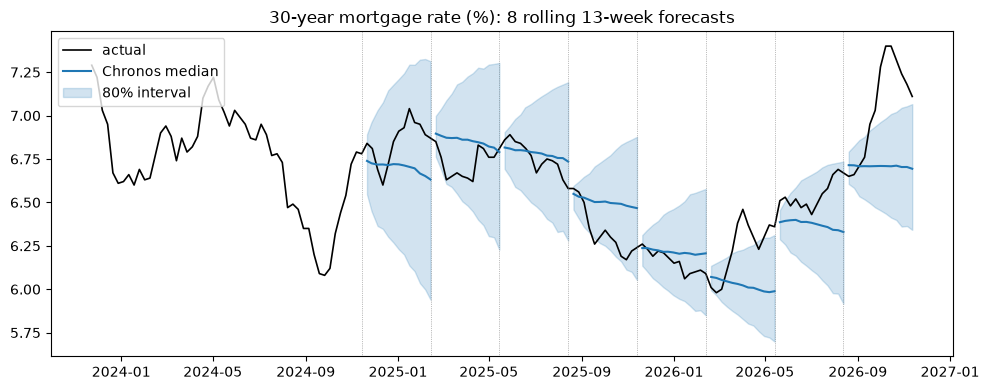

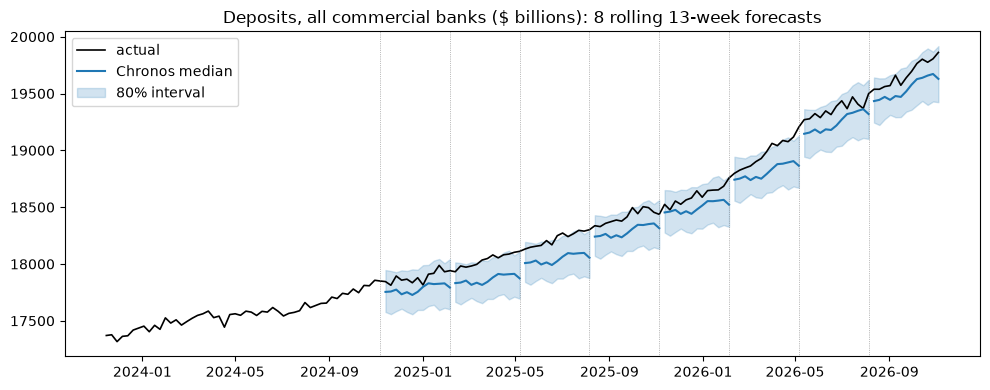

In [19]:
for name in SERIES:
    df = data[name]
    chronos = forecasts[(forecasts["series"] == name) & (forecasts["model"] == "chronos2")]
    shown = df.tail(N_WINDOWS * HORIZON + 52)

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(shown["timestamp"], shown["target"], color="black", linewidth=1.2, label="actual")
    for window, part in chronos.groupby("window"):
        ax.plot(part["timestamp"], part["forecast"], color="tab:blue",
                label="Chronos median" if window == 1 else None)
        ax.fill_between(part["timestamp"], part["lo80"], part["hi80"], color="tab:blue", alpha=0.2,
                        label="80% interval" if window == 1 else None)
        ax.axvline(part["origin"].iloc[0], color="gray", linewidth=0.5, linestyle=":")
    ax.set_title(SERIES[name]["label"] + ": 8 rolling 13-week forecasts")
    ax.legend(loc="upper left")
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"rolling_forecasts_{name}.svg")
    plt.show()

## 9. Save the results

- `output/forecasts_chronos.csv`: every Chronos and naive forecast in the common format.
- `output/evaluation_windows.csv`: the origin and the first and last forecast date of each window, for the ARIMA side to match.
- `output/metrics_chronos.csv`: the accuracy table above.

In [20]:
forecasts.to_csv(OUT_DIR / "forecasts_chronos.csv", index=False)
metrics.to_csv(OUT_DIR / "metrics_chronos.csv", index=False)

windows = (
    forecasts[forecasts["model"] == "chronos2"]
    .groupby(["series", "window"])
    .agg(origin=("origin", "first"), first_forecast=("timestamp", "min"), last_forecast=("timestamp", "max"))
    .reset_index()
)
windows.to_csv(OUT_DIR / "evaluation_windows.csv", index=False)
windows

,series,window,origin,first_forecast,last_forecast
0,deposits,1,2024-11-06,2024-11-13,2025-02-05
1,deposits,2,2025-02-05,2025-02-12,2025-05-07
2,deposits,3,2025-05-07,2025-05-14,2025-08-06
3,deposits,4,2025-08-06,2025-08-13,2025-11-05
4,deposits,5,2025-11-05,2025-11-12,2026-02-04
5,deposits,6,2026-02-04,2026-02-11,2026-05-06
6,deposits,7,2026-05-06,2026-05-13,2026-08-05
7,deposits,8,2026-08-05,2026-08-12,2026-11-04
8,mortgage30,1,2024-11-14,2024-11-21,2025-02-13
9,mortgage30,2,2025-02-13,2025-02-20,2025-05-15


## 10. Check: history length

Repeats the 8 forecasts for each series with shorter histories, to see whether the amount of history given to Chronos changes its forecasts. Results are saved to `output/check_context_length.csv`.

In [21]:
# ---- Check: does the length of history change the Chronos forecasts? ----
CONTEXT_WEEKS = {"full (from 2000)": None, "10 years": 520, "5 years": 260, "2 years": 104, "1 year": 52}

rows = []
for name in SERIES:
    df = data[name]
    for window, start in enumerate(window_positions(len(df)), start=1):
        actual = df.iloc[start : start + HORIZON]["target"].to_numpy()
        last_value = df["target"].iloc[start - 1]
        for label, weeks in CONTEXT_WEEKS.items():
            context = df.iloc[:start] if weeks is None else df.iloc[start - weeks : start]
            pred = pipeline.predict_df(
                context[CHRONOS_COLUMNS],
                prediction_length=HORIZON,
                quantile_levels=[0.1, 0.5, 0.9],
                id_column="item_id",
                timestamp_column="timestamp",
                target="target",
            )
            error = actual - pred["0.5"].to_numpy()
            inside = (actual >= pred["0.1"].to_numpy()) & (actual <= pred["0.9"].to_numpy())
            rows.append({
                "series": name,
                "context": label,
                "window": window,
                "last_value": last_value,
                "forecast_h1": pred["0.5"].iloc[0],
                "actual_h1": actual[0],
                "error_h1": error[0],
                "bias": error.mean(),
                "MAE": np.abs(error).mean(),
                "naive_MAE": np.abs(actual - last_value).mean(),
                "coverage80": inside.mean(),
            })

check = pd.DataFrame(rows)
check.to_csv(OUT_DIR / "check_context_length.csv", index=False)

check_summary = (
    check.groupby(["series", "context"], sort=False)[["error_h1", "bias", "MAE", "naive_MAE", "coverage80"]]
    .mean()
    .reset_index()
)
check_summary["relMAE"] = check_summary["MAE"] / check_summary["naive_MAE"]
check_summary.round(3)


,series,context,error_h1,bias,MAE,naive_MAE,coverage80,relMAE
0,mortgage30,full (from 2000),0.019,0.062,0.173,0.181,0.808,0.956
1,mortgage30,10 years,0.045,0.096,0.173,0.181,0.837,0.956
2,mortgage30,5 years,0.028,0.096,0.177,0.181,0.837,0.979
3,mortgage30,2 years,0.028,0.045,0.208,0.181,0.788,1.147
4,mortgage30,1 year,0.033,0.050,0.189,0.181,0.750,1.044
5,deposits,full (from 2000),95.613,138.158,138.158,137.137,0.875,1.007
6,deposits,10 years,39.481,46.820,69.241,137.137,0.981,0.505
7,deposits,5 years,1.781,25.670,56.884,137.137,0.865,0.415
8,deposits,2 years,16.854,60.455,83.678,137.137,0.769,0.610
9,deposits,1 year,19.678,42.029,62.159,137.137,0.760,0.453
